# Tahap 3 — Ekstraksi Fitur dan Visualisasi Representasi Suara

Notebook ini memetakan konsep **Pertemuan 8 — Pengenalan Pola Suara** ke data COUGHVID (Eksperimen A:
COVID-19 vs healthy *self-reported*). Fitur dihitung oleh `scripts/03_extract_features.py` (logika di
`src/features.py`); notebook hanya memuat hasil dan menampilkan grafik.

| Konsep materi | Representasi / fitur di notebook ini |
|---|---|
| Waveform, amplitudo, domain waktu | waveform COVID-19 vs healthy; RMS energy, ZCR, durasi |
| Fourier / FFT, domain frekuensi | spektrum FFT satu frame 32 ms; spectral centroid/bandwidth/rolloff/flatness/contrast |
| Spectrogram (STFT) | spectrogram linear, log-mel spectrogram |
| Pitch, periodik vs nonperiodik | f0 (`pyin`) dan rasio frame *voiced* — batuk dominan **nonperiodik** |
| Timbre | MFCC (+delta, delta-delta) dan GFCC (filterbank gammatone, R2/R3) |

**Catatan anti-leakage:** uji statistik, proyeksi PCA/t-SNE, dan rata-rata log-mel per kelas dihitung
**hanya pada split train**. Val/test tidak disentuh agar pemilihan fitur di Tahap 4 tetap jujur.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, librosa
from src.config import load_config, set_seed
from src import features as fx
from src.preprocessing import load_wav
from src.plots import (setup_style, save_fig, save_table, plot_waveform_pair, plot_fft_frame, plot_tf_grid,
                       plot_class_mean_logmel, plot_feature_violins, plot_projection)

cfg = load_config(); set_seed(cfg.seed); setup_style()
F = cfg.features; SR = cfg.audio.sample_rate; FD = cfg.paths.features
print(f"n_fft = {F.n_fft} ({1000*F.n_fft/SR:.0f} ms), hop = {F.hop_length} ({1000*F.hop_length/SR:.0f} ms), "
      f"resolusi frekuensi = {SR/F.n_fft:.2f} Hz, Nyquist = {SR//2} Hz")

n_fft = 512 (32 ms), hop = 160 (10 ms), resolusi frekuensi = 31.25 Hz, Nyquist = 8000 Hz


## 1. Ringkasan fitur yang diekstraksi

In [2]:
tab = pd.read_parquet(FD / 'tabular_A.parquet')
META = ['uuid', 'split', 'label', 'label_name']
FEAT = [c for c in tab.columns if c not in META]
print('Tabel fitur A:', tab.shape, '| jumlah fitur:', len(FEAT))
kel = pd.Series([fx.feature_group(c) for c in FEAT]).value_counts().rename('jumlah_kolom').to_frame()
display(kel)
print(pd.crosstab(tab.split, tab.label_name).loc[['train', 'val', 'test']])
summ = json.loads((cfg.paths.logs / 'features_summary.json').read_text(encoding='utf-8'))
for e, v in summ['eksperimen'].items():
    print(e, {s: d['shape_logmel'] for s, d in v['split'].items()}, '| mfcc2d', v['split']['train']['shape_mfcc2d'][1:])
print('Laporan NaN/inf (sebelum ditangani):')
display(pd.read_csv(cfg.paths.logs / 'features_nan_report.csv', index_col=0))

Tabel fitur A: (5255, 319) | jumlah fitur: 315


,jumlah_kolom
MFCC,78
GFCC,78
MFCC delta,52
MFCC delta-delta,52
spektral,40
waktu,9
pitch,6


label_name  COVID-19  healthy
split                        
train            502     1507
val              108     1514
test             108     1516
A {'train': [2009, 64, 1001], 'val': [1622, 64, 1001], 'test': [1624, 64, 1001]} | mfcc2d [40, 1001]
B {'train': [707, 64, 1001], 'val': [152, 64, 1001], 'test': [152, 64, 1001]} | mfcc2d [40, 1001]
Laporan NaN/inf (sebelum ditangani):


,eksperimen,n_inf,n_nan,penanganan
f0_mean,A,0,739,isi 0 (tidak ada frame voiced)
f0_std,A,0,739,isi 0 (tidak ada frame voiced)
f0_min,A,0,739,isi 0 (tidak ada frame voiced)
f0_max,A,0,739,isi 0 (tidak ada frame voiced)
f0_mean,B,0,144,isi 0 (tidak ada frame voiced)
f0_std,B,0,144,isi 0 (tidak ada frame voiced)
f0_min,B,0,144,isi 0 (tidak ada frame voiced)
f0_max,B,0,144,isi 0 (tidak ada frame voiced)


## 2. Contoh rekaman: domain waktu (waveform)
Satu rekaman COVID-19 dan satu healthy dari split train dipilih secara acak (seed 42) di antara rekaman
dengan 2–4 segmen batuk dan durasi 3–6 s agar representatif. Amplitudo sudah dinormalisasi *peak* (Tahap 2).

COVID-19: 936268f0-41a3-421d-bd18-8e69e597e84c | durasi 5.34 s | segmen batuk 4
healthy: c1e4b8f4-eed1-46cf-8471-859ca88e62bf | durasi 5.87 s | segmen batuk 2


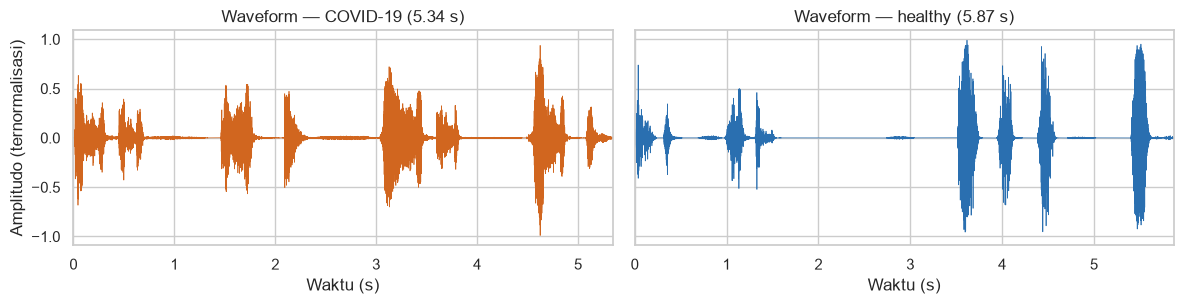

In [3]:
man = pd.read_csv(cfg.paths.processed / 'manifest_A.csv')
kand = man[(man.split == 'train') & man.n_segmen.between(2, 4) & man.durasi_trim_s.between(3, 6)]
ex_rows = {nm: kand[kand.label_name == nm].sample(1, random_state=cfg.seed).iloc[0] for nm in ['COVID-19', 'healthy']}
ex = {nm: load_wav(ROOT / r.path_wav)[0] for nm, r in ex_rows.items()}
for nm, r in ex_rows.items():
    print(f"{nm}: {r.uuid} | durasi {r.durasi_trim_s:.2f} s | segmen batuk {int(r.n_segmen)}")
fig = plot_waveform_pair(ex, SR); save_fig(fig, '03_waveform_covid_vs_healthy'); plt.show()

Batuk tampak sebagai **ledakan amplitudo singkat** (fase eksplosif) diikuti peluruhan, dipisah jeda.
Bentuk gelombang tidak berulang secara teratur → sinyal **nonperiodik**; tidak ada pola kasat mata yang
langsung membedakan kedua kelas di domain waktu.

## 3. Domain frekuensi: spektrum FFT satu frame
Frame 32 ms (512 sampel, jendela Hann) diambil pada puncak energi RMS. FFT 512 titik → 257 bin,
resolusi 16000/512 = 31,25 Hz, sampai frekuensi Nyquist 8 kHz.

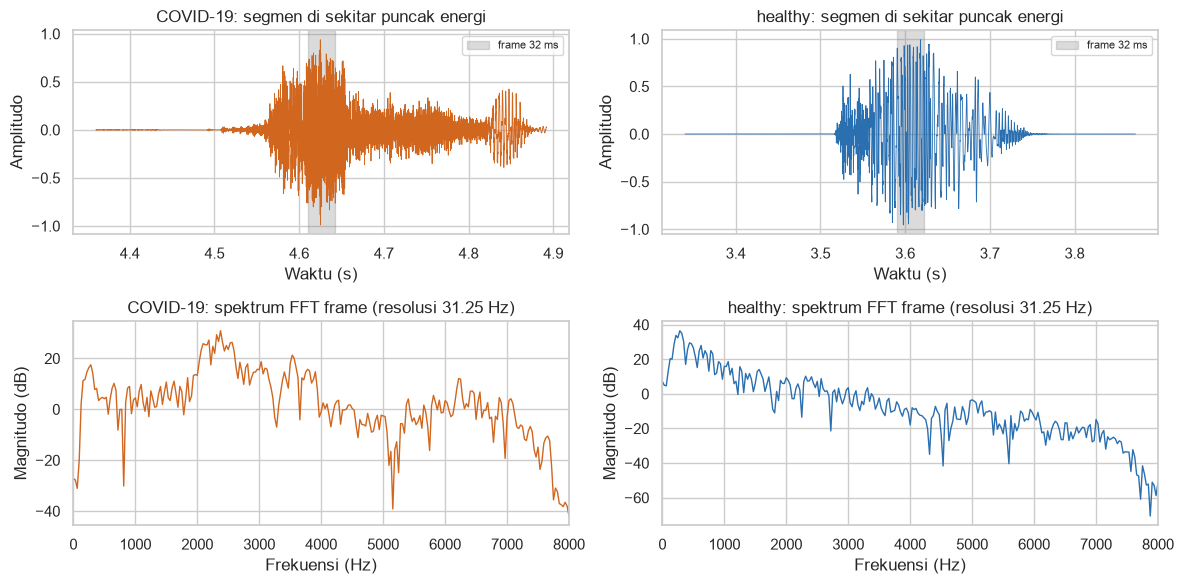

In [4]:
fig = plot_fft_frame(ex, SR, F.n_fft, F.hop_length); save_fig(fig, '03_spektrum_fft_frame'); plt.show()

Spektrum frame batuk **lebar pita (broadband)** tanpa deret harmonik yang jelas — ciri bunyi
nonperiodik mirip derau turbulen. Bila ada fase *voiced*, muncul puncak harmonik (kelipatan f0).

## 4. Representasi waktu–frekuensi: STFT, log-mel, MFCC, GFCC
Skala warna disamakan per baris agar kedua kelas sebanding.

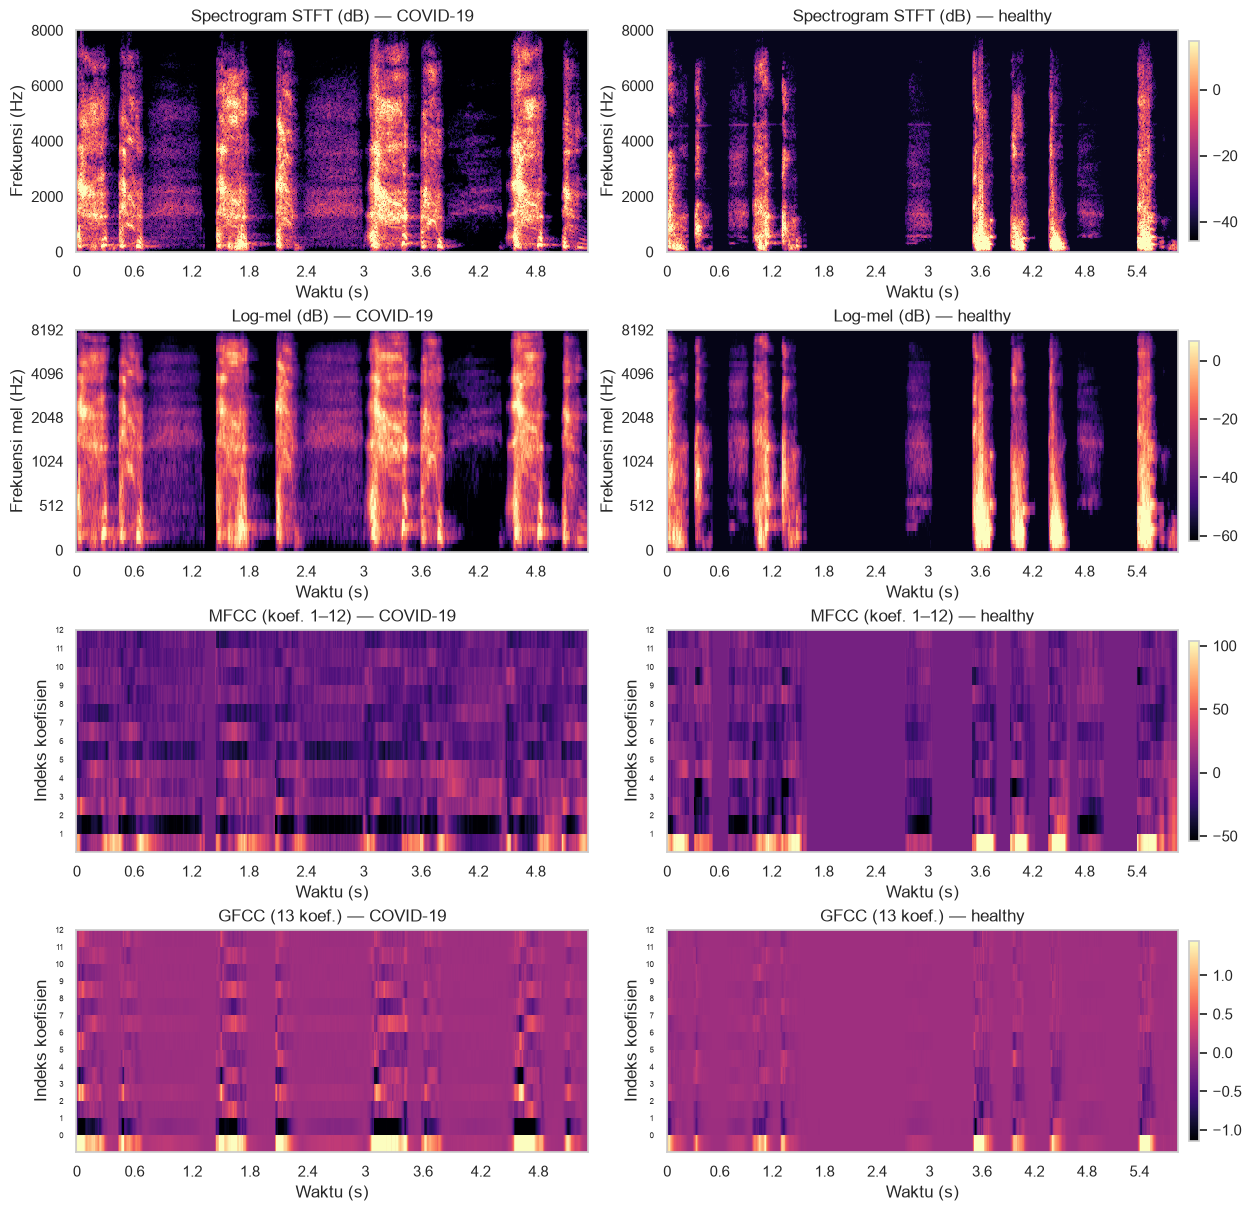

In [5]:
reps = {}
for nm, y in ex.items():
    S = fx.stft_mag(y, cfg)
    L = fx.logmel(y, SR, cfg)
    reps[nm] = {'Spectrogram STFT (dB)': librosa.amplitude_to_db(S, ref=1.0, top_db=F.top_db),
                'Log-mel (dB)': L,
                # c0 (≈ energi log, nilai ≈ −400) dibuang dari tampilan agar koef. 1–12 terlihat
                'MFCC (koef. 1–12)': librosa.feature.mfcc(y=y, sr=SR, n_mfcc=F.n_mfcc, n_fft=F.n_fft,
                                                          hop_length=F.hop_length, n_mels=F.n_mels)[1:],
                'GFCC (13 koef.)': fx.gfcc_matrix(y, SR, cfg)}
fig = plot_tf_grid(reps, SR, F.hop_length); save_fig(fig, '03_representasi_waktu_frekuensi'); plt.show()

- **Spectrogram STFT**: energi tersebar di seluruh pita 0–8 kHz saat batuk (vertikal "pita terang").
- **Log-mel**: sumbu frekuensi dikompresi sesuai persepsi telinga (lebih rinci di frekuensi rendah).
- **MFCC/GFCC**: ringkasan *selubung spektrum* (timbre) dalam 13 koefisien; koefisien ke-0 (≈ energi log) tidak ditampilkan untuk MFCC karena skalanya jauh lebih besar.
  GFCC memakai filter gammatone skala ERB (model koklea) dan cenderung lebih tahan noise (R2, R3).

## 5. Rata-rata log-mel per kelas (split train) dan selisihnya
Dihitung dari array input CNN (`logmel_A_train.npy`, 10 s, padding nol di akhir). Karena durasi rekaman
berbeda-beda, bagian kanan dipengaruhi padding (energi rendah) — perhatikan terutama 0–4 s pertama.

**Penting:** pita merah (COVID-19 lebih tinggi) di 1–5 s terutama mencerminkan **durasi** — rekaman COVID-19 sedikit lebih panjang (median 4,7 vs 4,0 s di train), sehingga lebih sedikit *padding* senyap; bukan beda timbre spesifik.

logmel_A_train: (2009, 64, 1001) float16


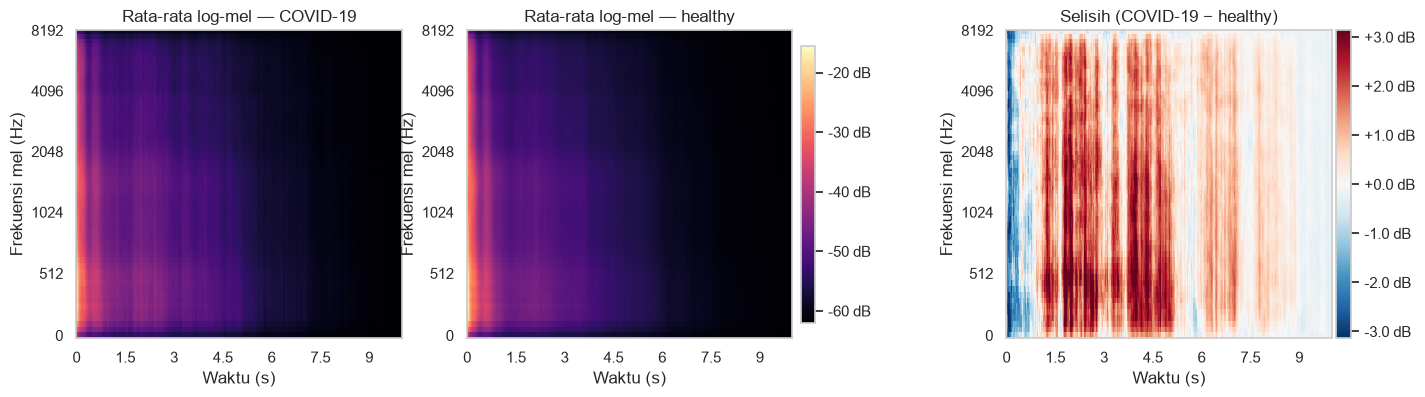

Selisih rata-rata COVID − healthy (0–4 s): min -0.36 dB, maks 1.62 dB, rata-rata |selisih| 0.93 dB


,0,8,16,24,32,40,48,56,63
frek_mel_Hz,0.00,383.00,766.00,1166.00,1731.00,2570.00,3814.00,5662.0,8000.00
selisih_dB_0_4s,0.41,1.41,0.94,0.91,1.07,0.81,0.83,0.9,-0.36


In [6]:
Ltr = np.load(FD / 'logmel_A_train.npy', mmap_mode='r'); ytr = np.load(FD / 'labels_A_train.npy')
print('logmel_A_train:', Ltr.shape, Ltr.dtype)
mean = fx.class_mean_2d(Ltr, ytr)
fig = plot_class_mean_logmel(mean[1], mean[0], SR, F.hop_length, F.fmax_mel)
save_fig(fig, '03_rata2_logmel_per_kelas'); plt.show()
D = mean[1] - mean[0]
mel_f = librosa.mel_frequencies(n_mels=F.n_mels, fmin=F.fmin_mel, fmax=F.fmax_mel)
prof = pd.DataFrame({'frek_mel_Hz': mel_f.round(0), 'selisih_dB_0_4s': D[:, :400].mean(1)})
print('Selisih rata-rata COVID − healthy (0–4 s): min %.2f dB, maks %.2f dB, rata-rata |selisih| %.2f dB'
      % (prof.selisih_dB_0_4s.min(), prof.selisih_dB_0_4s.max(), prof.selisih_dB_0_4s.abs().mean()))
display(prof.iloc[[0, 8, 16, 24, 32, 40, 48, 56, 63]].round(2).T)

## 6. Uji beda fitur antar kelas: Mann-Whitney U + ukuran efek (split train)
Uji nonparametrik (distribusi fitur tidak normal). Ukuran efek **rank-biserial r** (= Cliff's δ = 2·AUC − 1):
|r| ≈ 0,11 kecil, 0,28 sedang, 0,43 besar. **AUC fitur tunggal** = peluang nilai rekaman COVID-19 lebih
besar dari healthy (0,5 = tidak membedakan). p dikoreksi Benjamini–Hochberg (FDR) untuk 315 uji.

In [7]:
tr = tab[tab.split == 'train']
uji = fx.mann_whitney_table(tr, FEAT)
uji.insert(1, 'kelompok', uji.fitur.map(fx.feature_group))
save_table(uji, '03_uji_fitur_semua_A', index=False)
KOL = ['fitur', 'kelompok', 'median_covid', 'median_healthy', 'auc_fitur', 'rank_biserial_r', 'p_value', 'p_fdr']
top15 = uji.head(15)[KOL]
save_table(top15, '03_uji_fitur', index=False)
print(f"n train: COVID-19 = {(tr.label == 1).sum()}, healthy = {(tr.label == 0).sum()}")
print(f"Fitur signifikan (p_FDR < 0,05): {uji['signifikan_fdr_0.05'].sum()} dari {len(uji)}")
display(top15.style.format({'median_covid': '{:.3g}', 'median_healthy': '{:.3g}', 'auc_fitur': '{:.3f}',
                            'rank_biserial_r': '{:+.3f}', 'p_value': '{:.1e}', 'p_fdr': '{:.1e}'}))

n train: COVID-19 = 502, healthy = 1507
Fitur signifikan (p_FDR < 0,05): 39 dari 315


,fitur,kelompok,median_covid,median_healthy,auc_fitur,rank_biserial_r,p_value,p_fdr
0,contrast_05_std,spektral,8.22,7.22,0.584,+0.168,1.5e-08,4.8e-06
1,contrast_05_max,spektral,46.1,44.3,0.574,+0.149,5.9e-07,9.3e-05
2,rms_min,waktu,1.72e-05,2.03e-05,0.439,-0.122,3.3e-05,2.4e-03
3,durasi_s,waktu,4.66,3.99,0.561,+0.122,4.3e-05,2.4e-03
4,contrast_03_min,spektral,4.29,5.15,0.439,-0.121,4.5e-05,2.4e-03
5,mfcc_d_00_min,MFCC delta,-34.4,-32.4,0.439,-0.121,4.5e-05,2.4e-03
6,mfcc_08_min,MFCC,-39.4,-36.7,0.441,-0.119,6.8e-05,3.1e-03
7,contrast_02_min,spektral,2.72,3.08,0.441,-0.118,7.8e-05,3.1e-03
8,contrast_00_min,spektral,1.72,1.96,0.443,-0.113,1.4e-04,4.9e-03
9,flatness_std,spektral,0.0797,0.0692,0.556,+0.112,1.6e-04,5.1e-03


In [8]:
grp = (uji
          .groupby('kelompok').agg(n_fitur=('fitur', 'size'), n_signifikan=('signifikan_fdr_0.05', 'sum'),
                                   abs_r_maks=('abs_r', 'max'), abs_r_median=('abs_r', 'median'),
                                   fitur_terkuat=('fitur', 'first'))
          .sort_values('abs_r_maks', ascending=False))
save_table(grp, '03_uji_fitur_per_kelompok'); display(grp.round(3))

,n_fitur,n_signifikan,abs_r_maks,abs_r_median,fitur_terkuat
kelompok,,,,,
spektral,40,18,0.168,0.069,contrast_05_std
waktu,9,3,0.122,0.059,rms_min
MFCC delta,52,6,0.121,0.033,mfcc_d_00_min
MFCC,78,4,0.119,0.037,mfcc_08_min
GFCC,78,5,0.100,0.035,gfcc_00_min
MFCC delta-delta,52,3,0.096,0.035,mfcc_dd_04_min
pitch,6,0,0.072,0.037,f0_std


### Distribusi fitur kunci per kelas (violin + boxplot)
Fitur kunci dari materi (ZCR, RMS, centroid, rolloff, pitch, beberapa MFCC) + fitur dengan efek terbesar.

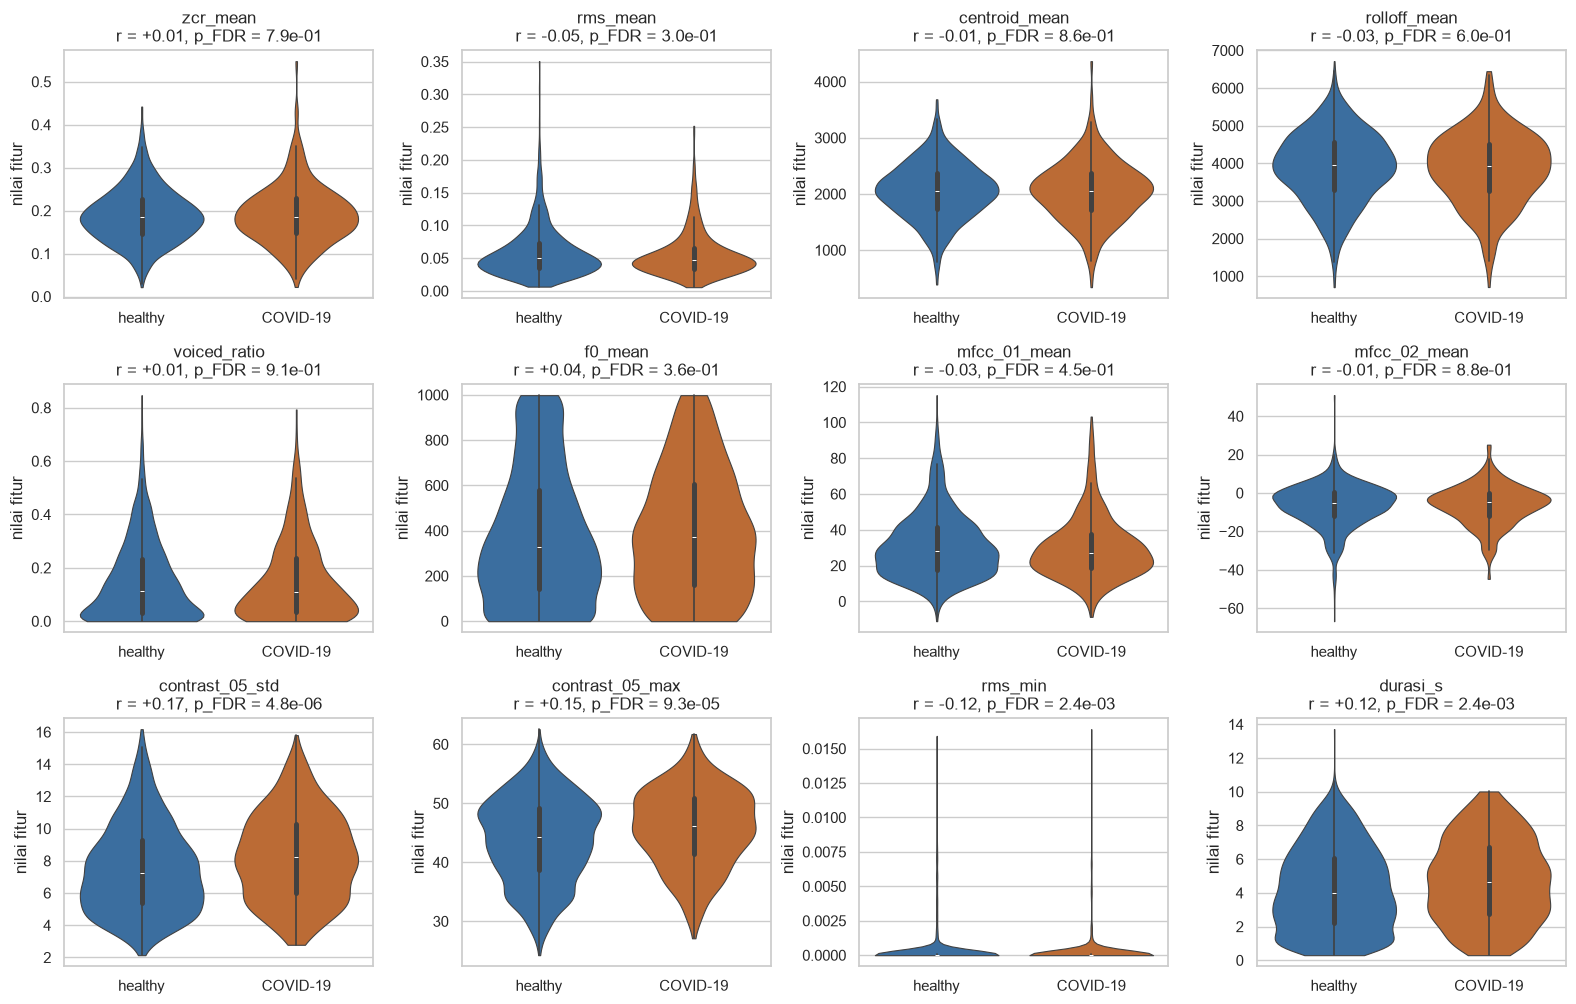

,auc_fitur,rank_biserial_r,p_fdr
fitur,,,
zcr_mean,0.5074,0.0147,0.7882
rms_mean,0.4774,-0.0452,0.3013
centroid_mean,0.4955,-0.0090,0.8617
rolloff_mean,0.4869,-0.0262,0.5981
voiced_ratio,0.5028,0.0056,0.9110
f0_mean,0.5201,0.0402,0.3614
mfcc_01_mean,0.4829,-0.0343,0.4491
mfcc_02_mean,0.4962,-0.0076,0.8803
contrast_05_std,0.5842,0.1684,0.0000


In [9]:
kunci = ['zcr_mean', 'rms_mean', 'centroid_mean', 'rolloff_mean', 'voiced_ratio', 'f0_mean',
         'mfcc_01_mean', 'mfcc_02_mean']
kunci += [f for f in uji.fitur if f not in kunci][:4]
fig = plot_feature_violins(tr, kunci, uji=uji); save_fig(fig, '03_violin_fitur_kunci'); plt.show()
display(uji.set_index('fitur').loc[kunci, ['auc_fitur', 'rank_biserial_r', 'p_fdr']].round(4))

### Seberapa besar overlap antar kelas?
Distribusi AUC fitur tunggal untuk 315 fitur; garis 0,5 = tak membedakan sama sekali.

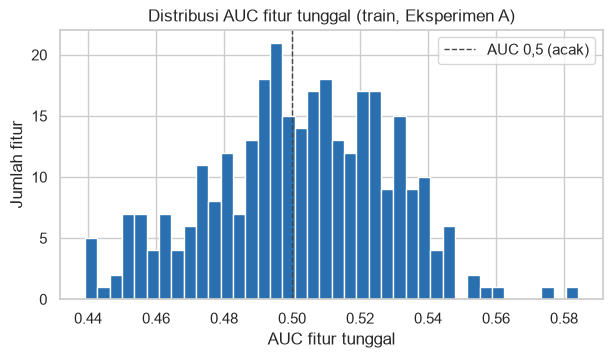

AUC fitur tunggal terjauh dari 0,5: contrast_05_std = 0.584
Fitur dengan |r| ≥ 0,11 (efek ≥ kecil): 10 | ≥ 0,28 (sedang): 0


In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(uji.auc_fitur, bins=40, color='#2a6fb0', edgecolor='white')
ax.axvline(0.5, color='#444444', ls='--', lw=1, label='AUC 0,5 (acak)')
ax.set(title='Distribusi AUC fitur tunggal (train, Eksperimen A)', xlabel='AUC fitur tunggal', ylabel='Jumlah fitur')
ax.legend(); save_fig(fig, '03_distribusi_auc_fitur'); plt.show()
far = (uji.auc_fitur - 0.5).abs()
print(f"AUC fitur tunggal terjauh dari 0,5: {uji.loc[far.idxmax(), 'fitur']} = {uji.loc[far.idxmax(), 'auc_fitur']:.3f}")
print(f"Fitur dengan |r| ≥ 0,11 (efek ≥ kecil): {(uji.abs_r >= 0.11).sum()} | ≥ 0,28 (sedang): {(uji.abs_r >= 0.28).sum()}")

### Pembanding: Eksperimen B (label ahli, split train)
Untuk Tahap 5 (keandalan label). Perhatikan fitur **durasi** — potensi *shortcut* (catatan Tahap 2).

In [11]:
tabB = pd.read_parquet(FD / 'tabular_B.parquet')
ujiB = fx.mann_whitney_table(tabB[tabB.split == 'train'], FEAT)
ujiB.insert(1, 'kelompok', ujiB.fitur.map(fx.feature_group))
save_table(ujiB.head(15)[KOL], '03_uji_fitur_B', index=False)
print(f"B train: COVID-19 = {(tabB[tabB.split=='train'].label==1).sum()}, healthy = {(tabB[tabB.split=='train'].label==0).sum()}")
print(f"B: fitur signifikan (p_FDR < 0,05): {ujiB['signifikan_fdr_0.05'].sum()} dari {len(ujiB)}")
display(ujiB.head(15)[KOL].round(4))
for e, u in (('A', uji), ('B', ujiB)):
    r = u.set_index('fitur').loc['durasi_s']
    print(f"{e}: durasi_s AUC = {r.auc_fitur:.3f}, r = {r.rank_biserial_r:+.3f}, peringkat |r| = {u.index[u.fitur == 'durasi_s'][0] + 1}")

B train: COVID-19 = 329, healthy = 378
B: fitur signifikan (p_FDR < 0,05): 178 dari 315


,fitur,kelompok,median_covid,median_healthy,auc_fitur,rank_biserial_r,p_value,p_fdr
0,durasi_s,waktu,4.912000,3.1040,0.6673,0.3346,0.0,0.0
1,mfcc_dd_09_max,MFCC delta-delta,2.666800,2.3104,0.6638,0.3275,0.0,0.0
2,mfcc_dd_11_min,MFCC delta-delta,-2.488800,-2.1379,0.3403,-0.3195,0.0,0.0
3,mfcc_d_09_max,MFCC delta,4.562500,3.8441,0.6590,0.3180,0.0,0.0
4,mfcc_d_11_min,MFCC delta,-4.168700,-3.4755,0.3438,-0.3125,0.0,0.0
5,mfcc_d_11_max,MFCC delta,4.219600,3.5320,0.6530,0.3060,0.0,0.0
6,mfcc_11_max,MFCC,26.383101,21.8328,0.6530,0.3060,0.0,0.0
7,mfcc_dd_11_max,MFCC delta-delta,2.576200,2.1931,0.6478,0.2956,0.0,0.0
8,mfcc_dd_09_min,MFCC delta-delta,-2.655200,-2.3249,0.3526,-0.2948,0.0,0.0
9,mfcc_d_08_max,MFCC delta,4.712700,4.0326,0.6458,0.2916,0.0,0.0


A: durasi_s AUC = 0.561, r = +0.122, peringkat |r| = 4
B: durasi_s AUC = 0.667, r = +0.335, peringkat |r| = 1


## 7. Proyeksi 2D: PCA dan t-SNE (split train Eksperimen A)
Fitur distandardisasi (z-score, di-*fit* pada sampel ini saja — hanya untuk visualisasi).
Jumlah sampel ≤ 3000 (train A = 2.009 setelah *undersampling*).

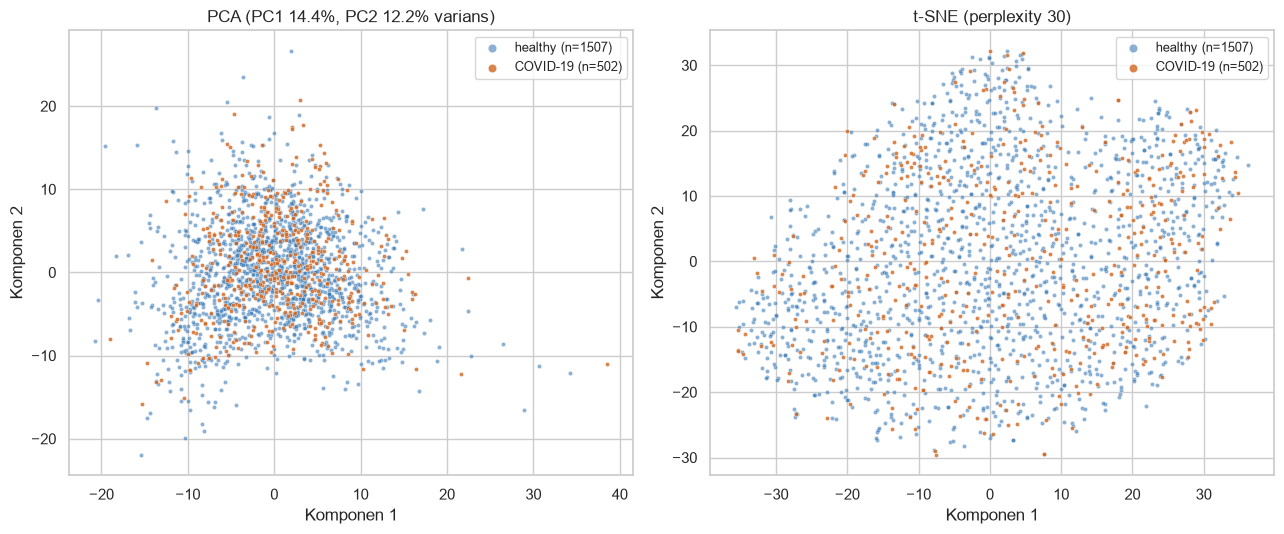

Varians kumulatif 2 PC = 26.6%, 10 PC = 48.2%, 50 PC = 76.4%
Silhouette (label sebagai klaster) — ruang fitur penuh: -0.006, t-SNE: +0.003


In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

samp = tr.sample(min(3000, len(tr)), random_state=cfg.seed)
X = StandardScaler().fit_transform(samp[FEAT].to_numpy(np.float64)); yl = samp.label.to_numpy()
pca = PCA(n_components=50, random_state=cfg.seed).fit(X)
Zp = pca.transform(X)[:, :2]
Zt = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=cfg.seed).fit_transform(X)
ev = pca.explained_variance_ratio_
fig = plot_projection({f'PCA (PC1 {ev[0]:.1%}, PC2 {ev[1]:.1%} varians)': Zp, 't-SNE (perplexity 30)': Zt}, yl)
save_fig(fig, '03_proyeksi_pca_tsne'); plt.show()
print(f"Varians kumulatif 2 PC = {ev[:2].sum():.1%}, 10 PC = {ev[:10].sum():.1%}, 50 PC = {ev.sum():.1%}")
print(f"Silhouette (label sebagai klaster) — ruang fitur penuh: {silhouette_score(X, yl):+.3f}, t-SNE: {silhouette_score(Zt, yl):+.3f}")

## 8. Kesimpulan sementara
Lihat angka pada sel-sel di atas; ringkasan naratif ada di `PROGRESS.md` (Tahap 3). Intinya: tidak ada
satu fitur pun yang memisahkan COVID-19 dan healthy dengan baik — distribusi kedua kelas **sangat
tumpang-tindih**, sejalan dengan sifat label *self-reported* COUGHVID (R4). Pemisahan (bila ada) harus
didapat dari kombinasi banyak fitur oleh classifier di Tahap 4.